# Object Detection Preceded by a Pre-Trained Model: YOLOv8 + DINOv2
**DA 232o Intelligent User Interfaces · Midterm Assignment**

### Objective
> *Implement a computer vision model for object detection preceded by a pre-trained model. Select a standard dataset and explain the utility of the pre-trained model.*

This notebook implements the **YOLOv8 + DINOv2** design from the IISc I3D Lab's *AI resource for Design & Manufacturing* page, trains it on **Pascal VOC**, and measures what the pre-trained model adds by comparing it with an identical detector that does not have it.

### Approach in one paragraph
YOLOv8 is a fast object detector, but it learns only from the labelled boxes it is trained on. **DINOv2** (Meta AI) is a large vision model pre-trained **without any labels** on about 142 million images, and it has learned a general understanding of scenes and objects. Before YOLO's detection head makes its decision, the raw image is also passed through the **frozen** DINOv2, whose whole-image summary (a 384-number *global embedding*) is joined to YOLO's deepest feature map. YOLO therefore receives a hint about *what kind of scene it is looking at* while it works out *where* each object is.

### Experiment design
| | Run A: baseline | Run B: proposed |
|---|---|---|
| Model | YOLOv8n | YOLOv8n + DINOv2 (frozen ViT-S/14) |
| Starting weights | COCO pre-trained YOLOv8n | the same COCO weights + DINOv2's own weights |
| Data, epochs, image size, batch, seed | identical | identical |

The **only** difference between the two runs is the DINOv2 hint, so any difference in the results can be attributed to the pre-trained model (see *Limitations* for one caveat).

### Notebook structure
1–3: configuration and installation · 4–7: building the model · 8: dataset characteristics · 9: sanity check · 10–11: training · 12–16: evaluation and visual comparison · 17: saving outputs · 18–20: discussion, conclusion, limitations

**Hardware used:** Kaggle notebook with an NVIDIA Tesla T4 GPU (16 GB).

## 1. Configuration
All experiment settings are kept in one place.
- `RUN_MODE = "smoke"` runs a 2-epoch check on 8 images to confirm that the code works; `"full"` runs the real experiment.
- **Epochs = 30:** each model sees all 16,551 training photos 30 times.
- **Image size = 640:** photos are resized to 640 × 640 pixels for YOLO.
- **Batch = 32:** 32 photos are processed per training step.
- **Seed = 0:** randomness (photo order, augmentation) is fixed so that both runs, and any re-run, are directly comparable.
- The dataset is stored in `/tmp/datasets`, outside `/kaggle/working`, so the several-GB download is not copied into the saved output.

In [1]:
# "smoke" = quick check on 8 images (minutes).  "full" = real experiment on Pascal VOC (hours).
RUN_MODE = "full"

EPOCHS = 30        # full mode: rounds through the whole training set (same for both models)
IMGSZ = 640        # image size YOLO trains on
BATCH = 32         # photos per training step (lower to 16 if you get an "out of memory" error)
SEED = 0           # fixed randomness, so both runs are comparable
RUN_BASELINE = True
RUN_DINO = True

import os, torch
WORK = "/kaggle/working" if os.path.isdir("/kaggle/working") else os.getcwd()
RUNS = os.path.join(WORK, "runs")
DATASETS = "/tmp/datasets"   # large download kept outside /kaggle/working (20 GB output limit)
DEVICE = 0 if torch.cuda.is_available() else "cpu"

if RUN_MODE == "smoke":
    DATA, EPOCHS, BATCH = "coco8.yaml", 2, 8
else:
    DATA = "VOC.yaml"
print(f"Mode={RUN_MODE}  data={DATA}  epochs={EPOCHS}  device={DEVICE}")

Mode=full  data=VOC.yaml  epochs=30  device=0


## 2. Environment check
Confirms that a GPU is attached and that PyTorch can use it (CUDA). Training on a CPU would take days instead of hours.

In [2]:
!nvidia-smi --query-gpu=name,memory.total --format=csv || echo "No GPU found (fine for smoke mode, too slow for full mode)"
print("PyTorch", torch.__version__, "| CUDA available:", torch.cuda.is_available())

name, memory.total [MiB]
Tesla T4, 15360 MiB
Tesla T4, 15360 MiB
PyTorch 2.10.0+cu128 | CUDA available: True


## 3. Installing Ultralytics (YOLOv8)
The Ultralytics library provides YOLOv8, its training loop, data augmentation and evaluation. The version is **pinned** (`8.4.170`) because the next sections modify the library's internal code, and a different version could change that code.

In [3]:
!pip install -q "ultralytics==8.4.170"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 462.6 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.2/95.2 kB 4.5 MB/s eta 0:00:00


## 4. Model architecture: the pre-trained model and the fusion layer
This cell writes the two new network layers to a file.

### 4.1 The two pre-trained models used
| Model | Pre-trained on | How it learned | Role here |
|---|---|---|---|
| **YOLOv8n** (Ultralytics) | COCO: about 118,000 images, 80 classes | supervised, from labelled boxes | the object detector being trained |
| **DINOv2 ViT-S/14** (Meta AI) | LVD-142M: about 142 million curated images | **self-supervised**: no labels at all | frozen feature extractor that provides scene context |

DINOv2 learns by *self-distillation*: a "student" network is trained to produce the same representation as a "teacher" network for different crops and distortions of the same image. Because no human labels are needed, it can learn from a far larger and more varied collection of images than any labelled detection dataset, and it learns general notions of shape, object parts and scene layout.

### 4.2 Data flow through the network
```
                 ┌──────────── YOLOv8 backbone (CSP-Darknet) ────────────┐
 image 640×640 ─►│ Conv … C2f … SPPF  →  feature map 20×20×256 (stride 32)│──┐
       │         └────────────────────────────────────────────────────────┘  │   concatenate     1×1 conv       YOLOv8 head
       │                                                                      ├──► 20×20×640 ──► 20×20×256 ──► (neck + Detect)
       │      resize 224×224      frozen DINOv2      global embedding         │                                 boxes + classes
       └────► + ImageNet norm ───► ViT-S/14  ──────► 384 numbers ──► LayerNorm ┘
                                                         (copied onto all 20×20 cells)
```

### 4.3 The two layers
- **`InputPass`** (the lab page's `ConvDummy`) returns its input unchanged. Placed at position 0, it lets a later layer request "the output of layer 0", that is, the raw image.
- **`DINOFusion`**
  1. resizes the image to 224 × 224 and applies the ImageNet normalisation DINOv2 was trained with;
  2. runs the **frozen** DINOv2 and takes its normalised CLS token, a 384-number summary of the whole image;
  3. copies that summary onto every cell of YOLO's 20 × 20 deepest feature grid;
  4. concatenates it with YOLO's 256 feature channels (256 + 384 = 640 channels), exactly as on the lab page;
  5. a learnable **1 × 1 convolution** mixes the 640 channels back to 256, so the rest of YOLO is unchanged and keeps its pre-trained weights.

### 4.4 Changes from the lab page's version, and why
| Change | Reason |
|---|---|
| **Safe start:** the 1 × 1 convolution is initialised to pass YOLO's channels through unchanged, with zero weight on DINOv2's channels | At the start the model is *exactly* the pre-trained YOLOv8n, so training can only learn to use the hint if it helps. This keeps the comparison with the baseline fair. |
| ImageNet mean/std normalisation (instead of 0.5/0.5) | DINOv2 was trained with ImageNet statistics. |
| DINOv2 sees a 224 × 224 copy | Only one global summary is needed, and 224 is much faster than 518. |
| Loaded from Hugging Face (`facebook/dinov2-small`) | The same model as the lab's `dinov2_vits14`, but saved checkpoints reload reliably. |
| `train()` keeps DINOv2 in evaluation mode | DINOv2 behaves identically during training and testing. |

In [4]:
%%writefile dino_fusion.py
"""
YOLOv8 + DINOv2 global-context fusion layers.

This file is copied into the Ultralytics package as
ultralytics/nn/modules/dino_fusion.py by the setup cell of the notebook.

Two layers are defined:

1. InputPass  (the lab page calls it "ConvDummy")
   A do-nothing layer placed at position 0 of the network. It returns the
   raw image unchanged, so that a later layer can ask for "the output of
   layer 0" and receive the original photo.

2. DINOFusion
   Receives two inputs: [YOLO's deepest feature map, the raw image].
   - Runs the frozen, pre-trained DINOv2 on the raw image and takes its
     global summary vector (384 numbers for the small model).
   - Stretches that vector over every cell of YOLO's feature grid.
   - Joins (concatenates) it with YOLO's features, exactly as on the lab page.
   - A 1x1 convolution squeezes the result back to YOLO's original channel
     count, so the rest of YOLO (the "head") is unchanged and can reuse its
     pre-trained weights.

   Safe start: that 1x1 convolution is initialised so that, before training,
   it passes YOLO's features through unchanged and ignores DINOv2. The model
   therefore starts exactly equal to pre-trained YOLOv8, and training decides
   how much of DINOv2's hint to use. This keeps the comparison with the
   baseline fair.
"""

import torch
import torch.nn as nn
import torch.nn.functional as F

__all__ = ("InputPass", "DINOFusion")

# DINOv2 was trained on images normalised with ImageNet statistics.
_IMAGENET_MEAN = (0.485, 0.456, 0.406)
_IMAGENET_STD = (0.229, 0.224, 0.225)


class InputPass(nn.Module):
    """Return the input unchanged (the lab page's ConvDummy)."""

    def __init__(self, *args, **kwargs):
        super().__init__()

    def forward(self, x):
        return x


class DINOFusion(nn.Module):
    """Inject DINOv2's global scene embedding into a YOLO feature map.

    Args:
        c1 (int): channels of the YOLO feature map coming in (filled in by the config reader).
        model_name (str): Hugging Face name of the DINOv2 model.
        dino_imgsz (int): image size DINOv2 looks at. Must be a multiple of 14.
            224 is used because only one global summary is needed, and it is
            far faster than larger sizes.
    """

    def __init__(self, c1, model_name="facebook/dinov2-small", dino_imgsz=224):
        super().__init__()
        from transformers import Dinov2Model  # imported here so YOLO loads even if transformers is absent

        self.dino = Dinov2Model.from_pretrained(model_name)
        self.dino.requires_grad_(False)  # frozen: DINOv2's knowledge is not changed
        self.dino.eval()

        d = self.dino.config.hidden_size  # 384 for dinov2-small
        self.dino_imgsz = int(round(dino_imgsz / 14) * 14)
        self.register_buffer("mean", torch.tensor(_IMAGENET_MEAN).view(1, 3, 1, 1), persistent=False)
        self.register_buffer("std", torch.tensor(_IMAGENET_STD).view(1, 3, 1, 1), persistent=False)

        # Learnable parts (these are trained):
        self.norm = nn.LayerNorm(d)  # keeps the DINOv2 numbers on a sensible scale
        self.fuse = nn.Conv2d(c1 + d, c1, kernel_size=1, bias=True)  # concat -> back to c1 channels

        # Safe start: identity on YOLO's channels, zero on DINOv2's channels.
        with torch.no_grad():
            self.fuse.weight.zero_()
            self.fuse.bias.zero_()
            for i in range(c1):
                self.fuse.weight[i, i, 0, 0] = 1.0

    def train(self, mode=True):
        """Keep DINOv2 in evaluation mode even while YOLO trains."""
        super().train(mode)
        self.dino.eval()
        return self

    def _global_embedding(self, img):
        x = F.interpolate(img.float(), size=(self.dino_imgsz, self.dino_imgsz), mode="bilinear", align_corners=False)
        x = (x - self.mean) / self.std
        with torch.no_grad():
            out = self.dino(pixel_values=x)
        return out.pooler_output  # (batch, 384): the normalised CLS token = whole-image summary

    def forward(self, x):
        feat, img = x  # [YOLO feature map, raw image]
        emb = self.norm(self._global_embedding(img).to(feat.dtype))  # (B, 384)
        emb = emb[:, :, None, None].expand(-1, -1, feat.shape[2], feat.shape[3])  # copy onto every grid cell
        return self.fuse(torch.cat([feat, emb], dim=1))

Writing dino_fusion.py


## 5. Integrating the layers with Ultralytics and transferring pre-trained weights
The lab page's setup steps are incomplete. This helper fixes the missing parts:
1. **Registering the layers.** The layer file is copied into the Ultralytics package, and YOLO's configuration reader (`parse_model` in `tasks.py`) is taught the input and output channel sizes of `DINOFusion`. Without this, the network cannot be built.
2. **Transferring COCO weights.** Adding two layers shifts every layer number (backbone layers +1, head layers +2). The helper renames each pre-trained weight to its new position before copying. Without this step the modified model would start from random weights, which would be unfair to it compared with the pre-trained baseline.
3. Marking the model as "loaded" so that YOLO's trainer keeps these weights instead of rebuilding the model from scratch.

In [5]:
%%writefile setup_dino.py
"""
Setup helper: teaches Ultralytics about the two new layers and copies the
pre-trained YOLOv8n weights into the shifted YOLOv8n+DINOv2 layout.

Usage (in the notebook):
    import setup_dino
    setup_dino.install()                      # once per session, BEFORE importing YOLO
    from ultralytics import YOLO
    model = setup_dino.build_dino_model("yolov8n-dino.yaml", "yolov8n.pt")
"""

import os
import re
import shutil

PATCH_MARK = "# >>> DINOFusion patch"


def install(module_file=None):
    """Copy dino_fusion.py into Ultralytics and register the layers with its config reader.

    Safe to run more than once. Must run before `from ultralytics import YOLO`
    in a fresh session (or restart the session after running it).
    """
    import importlib.util

    spec = importlib.util.find_spec("ultralytics")
    pkg = os.path.dirname(spec.origin)
    here = os.path.dirname(os.path.abspath(__file__))
    module_file = module_file or os.path.join(here, "dino_fusion.py")

    # 1. Put the layer code inside the package (so saved checkpoints can be reloaded later).
    shutil.copy(module_file, os.path.join(pkg, "nn", "modules", "dino_fusion.py"))

    # 2. Teach the config reader (parse_model in tasks.py) about the new layers.
    tasks = os.path.join(pkg, "nn", "tasks.py")
    src = open(tasks, encoding="utf-8").read()
    if PATCH_MARK not in src:
        anchor = "        elif m is CBFuse:"
        if anchor not in src:
            raise RuntimeError("Could not find the place to patch in tasks.py; check the Ultralytics version.")
        branch = (
            f"        elif m is DINOFusion:  {PATCH_MARK}\n"
            "            c1 = ch[f[0]]  # channels of the YOLO feature map\n"
            "            c2 = c1  # output keeps the same channel count\n"
            "            args = [c1, *args]\n"
        )
        src = src.replace(anchor, branch + anchor, 1)
        src += f"\n\n{PATCH_MARK} (imports)\nfrom ultralytics.nn.modules.dino_fusion import DINOFusion, InputPass  # noqa: E402\n"
        open(tasks, "w", encoding="utf-8").write(src)
        print("Ultralytics patched: DINOFusion and InputPass registered.")
    else:
        print("Ultralytics already patched.")


def shift_index(i):
    """Map a layer number in standard YOLOv8 to the YOLOv8+DINO layout.

    Standard layers 0-9 (backbone) move up by 1 (InputPass is now layer 0).
    Standard layers 10-22 (head) move up by 2 (InputPass + DINOFusion).
    """
    return i + 1 if i <= 9 else i + 2


def build_dino_model(cfg="yolov8n-dino.yaml", pretrained="yolov8n.pt"):
    """Build YOLOv8+DINOv2 and copy every matching pre-trained YOLOv8 weight into it."""
    from ultralytics import YOLO

    donor = YOLO(pretrained).model.float().state_dict()
    model = YOLO(cfg)
    own = model.model.state_dict()

    moved = {}
    for k, v in donor.items():
        m = re.match(r"model\.(\d+)\.(.*)", k)
        if not m:
            continue
        new_k = f"model.{shift_index(int(m.group(1)))}.{m.group(2)}"
        if new_k in own and own[new_k].shape == v.shape:
            moved[new_k] = v

    model.model.load_state_dict(moved, strict=False)
    yolo_keys = [k for k in own if ".dino." not in k and not k.startswith("model.11.")]
    print(f"Copied {len(moved)}/{len(yolo_keys)} YOLO weight tensors from {pretrained} "
          f"(DINOv2 keeps its own pre-trained weights; only the new fusion layer starts fresh).")

    # Mark the model as 'loaded', so model.train() keeps these weights instead of starting from random.
    model.load(model.model)
    return model

Writing setup_dino.py


## 6. Model configuration (YAML)
The blueprint of the network, read line by line by YOLO. It is the standard `yolov8.yaml` (nano scale) with layer 0 (`InputPass`) and layer 11 (`DINOFusion`) added. Every layer reference in the head is updated for the shifted numbering; this is the part the lab page omits. Layer 22 now concatenates the **DINO-enriched** features (layer 11) into the large-object detection branch.

In [6]:
%%writefile yolov8n-dino.yaml
# YOLOv8n + DINOv2 global-context fusion
# Same as the standard yolov8.yaml, with two changes:
#   - layer 0 (InputPass) passes the raw image through, so layer 11 can read it
#   - layer 11 (DINOFusion) joins DINOv2's scene summary to YOLO's deepest features
# Because of these two extra layers, every layer number below is shifted
# compared to the standard file, and the head's references are updated to match.

nc: 80 # number of classes (replaced automatically by the dataset's class count)
scale: n
scales:
  # [depth, width, max_channels]
  n: [0.33, 0.25, 1024]
  s: [0.33, 0.50, 1024]

backbone:
  # [from, repeats, module, args]
  - [-1, 1, InputPass, []] # 0  raw image (lab page: ConvDummy)
  - [-1, 1, Conv, [64, 3, 2]] # 1  P1/2  (standard layer 0)
  - [-1, 1, Conv, [128, 3, 2]] # 2  P2/4
  - [-1, 3, C2f, [128, True]] # 3
  - [-1, 1, Conv, [256, 3, 2]] # 4  P3/8
  - [-1, 6, C2f, [256, True]] # 5
  - [-1, 1, Conv, [512, 3, 2]] # 6  P4/16
  - [-1, 6, C2f, [512, True]] # 7
  - [-1, 1, Conv, [1024, 3, 2]] # 8  P5/32
  - [-1, 3, C2f, [1024, True]] # 9
  - [-1, 1, SPPF, [1024, 5]] # 10 end of YOLO backbone (standard layer 9)
  - [[10, 0], 1, DINOFusion, ["facebook/dinov2-small", 224]] # 11 DINOv2 scene summary joined here

head:
  - [-1, 1, nn.Upsample, [None, 2, "nearest"]] # 12
  - [[-1, 7], 1, Concat, [1]] # 13 cat backbone P4
  - [-1, 3, C2f, [512]] # 14
  - [-1, 1, nn.Upsample, [None, 2, "nearest"]] # 15
  - [[-1, 5], 1, Concat, [1]] # 16 cat backbone P3
  - [-1, 3, C2f, [256]] # 17 (P3/8-small)
  - [-1, 1, Conv, [256, 3, 2]] # 18
  - [[-1, 14], 1, Concat, [1]] # 19 cat head P4
  - [-1, 3, C2f, [512]] # 20 (P4/16-medium)
  - [-1, 1, Conv, [512, 3, 2]] # 21
  - [[-1, 11], 1, Concat, [1]] # 22 cat head P5 (now the DINO-enriched features)
  - [-1, 3, C2f, [1024]] # 23 (P5/32-large)
  - [[17, 20, 23], 1, Detect, [nc]] # 24 Detect(P3, P4, P5)

Writing yolov8n-dino.yaml


## 7. Applying the setup
Patches Ultralytics **before** importing YOLO (Python reads a library's code only once), then points YOLO's dataset folder to `/tmp/datasets` for this session.

In [7]:
import setup_dino
setup_dino.install()          # must run before importing YOLO

from pathlib import Path
from ultralytics import YOLO, settings
import ultralytics.data.utils as data_utils
settings.update({"datasets_dir": DATASETS})   # remembered for future sessions
data_utils.DATASETS_DIR = Path(DATASETS)      # applied to this session too

Ultralytics patched: DINOFusion and InputPass registered.
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


## 8. Dataset characteristics
What the data looks like before any training: how many photos and labelled objects are in the training and test sets, how many objects each class has (class balance), how many objects a photo usually contains, how big the objects are, the photo sizes, and a few training photos with their labelled boxes. In full mode this cell also downloads Pascal VOC.


WARNING ⚠️ Dataset 'VOC.yaml' images not found, missing path '/tmp/datasets/VOC/images/test2007'
Unzipping /tmp/datasets/VOC/images/VOCtest_06-Nov-2007.zip to /tmp/datasets/VOC/images/VOCdevkit...: 100% ━━━━━━━━━━━━ 10357/10357 1.1Kfiles/s 9.3s
Unzipping /tmp/datasets/VOC/images/VOCtrainval_06-Nov-2007.zip to /tmp/datasets/VOC/images/VOCdevkit...: 100% ━━━━━━━━━━━━ 10945/10945 1.2Kfiles/s 9.0s
Unzipping /tmp/datasets/VOC/images/VOCtrainval_11-May-2012.zip to /tmp/datasets/VOC/images/VOCdevkit...: 100% ━━━━━━━━━━━━ 40189/40189 1.7Kfiles/s 23.1s
train2012: 100% ━━━━━━━━━━━━ 5717/5717 3.0Kit/s 1.9s
val2012: 100% ━━━━━━━━━━━━ 5823/5823 2.8Kit/s 2.1s
train2007: 100% ━━━━━━━━━━━━ 2501/2501 3.3Kit/s 0.8s
val2007: 100% ━━━━━━━━━━━━ 2510/2510 3.3Kit/s 0.8s
test2007: 100% ━━━━━━━━━━━━ 4952/4952 993.2it/s 5.0s
Dataset download success ✅ (88.0s), saved to /tmp/datasets

Dataset: VOC.yaml   |   20 classes: aeroplane, bicycle, bird, boat, bottle, bus, car, cat, chair, cow, diningtable, dog, horse, 

,images,labelled objects,avg objects per image
train,16551,40058,2.42
test,4952,12032,2.43


,train images,train objects,test images,test objects
class,,,,
person,6095,13256,2007,4528
car,1874,3267,721,1201
chair,1564,3152,417,756
dog,1707,2025,418,489
bottle,950,1764,212,469
bird,1095,1605,282,459
cat,1417,1593,322,358
pottedplant,772,1487,224,480
aeroplane,908,1171,204,285


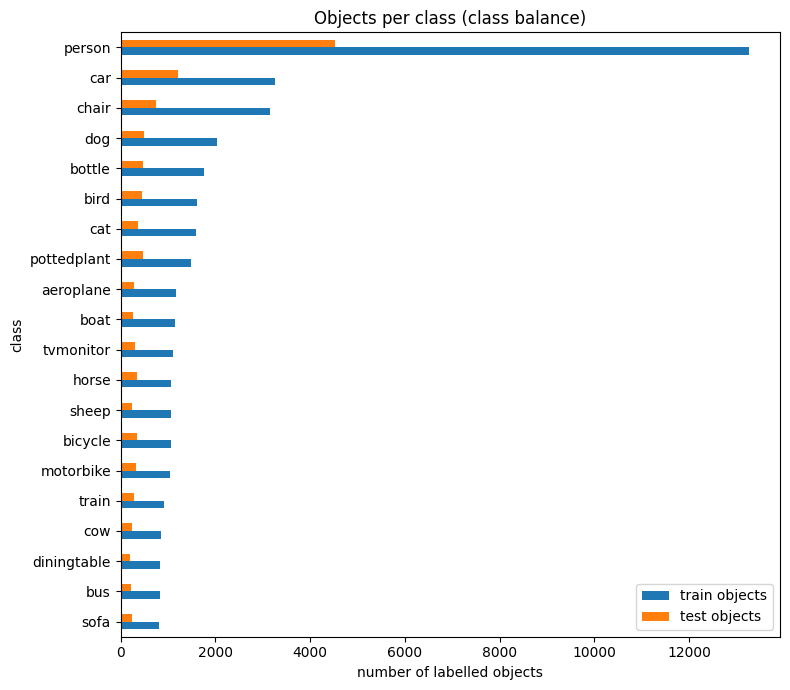

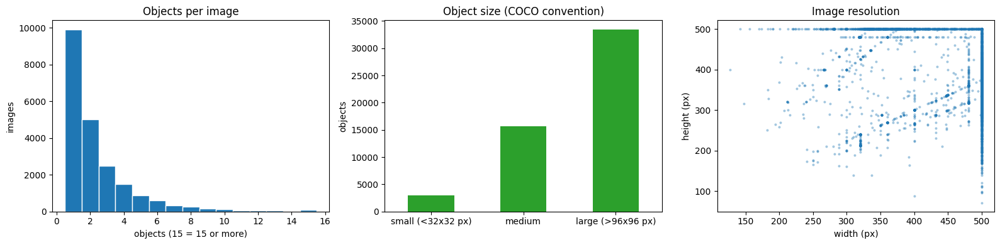

Object sizes: {'small (<32x32 px)': 5.7, 'medium': 30.1, 'large (>96x96 px)': 64.2} (% of objects)
Most common image sizes (w x h): {'500x375': 9047, '500x333': 2934, '375x500': 1776}


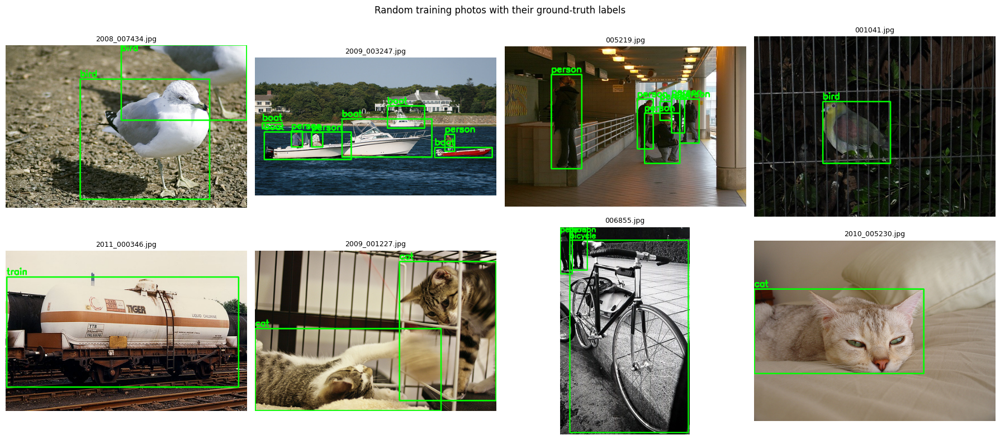

In [8]:
import glob, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from PIL import Image
from ultralytics.data.utils import check_det_dataset, img2label_paths

info = check_det_dataset(DATA)          # downloads + converts the dataset the first time
CLASS_NAMES = info["names"]             # {0: 'aeroplane', 1: 'bicycle', ...}
os.makedirs(os.path.join(WORK, "results"), exist_ok=True)

def list_images(split):
    folders = split if isinstance(split, list) else [split]
    return sorted(f for d in folders for f in glob.glob(os.path.join(d, "*.jpg")))

def read_split(split_name, folders):
    """One row per labelled object: which image, which class, box size, image size."""
    rows, n_images = [], 0
    for img in list_images(folders):
        n_images += 1
        w, h = Image.open(img).size     # reads only the file header, so it is fast
        lab = img2label_paths([img])[0]
        if not os.path.exists(lab):
            continue
        for line in open(lab):
            p = line.split()
            if len(p) < 5:
                continue
            c, xc, yc, bw, bh = int(p[0]), *map(float, p[1:5])
            rows.append({"split": split_name, "image": img, "class": CLASS_NAMES[c],
                         "img_w": w, "img_h": h, "box_area_px": bw * w * bh * h, "box_area_frac": bw * bh})
    return pd.DataFrame(rows), n_images

train_df, n_train = read_split("train", info["train"])
test_df, n_test = read_split("test", info["val"])
objs = pd.concat([train_df, test_df], ignore_index=True)

# 1. Overall summary
summary_ds = pd.DataFrame({
    "images": [n_train, n_test],
    "labelled objects": [len(train_df), len(test_df)],
    "avg objects per image": [len(train_df) / max(n_train, 1), len(test_df) / max(n_test, 1)],
}, index=["train", "test"]).round(2)
print(f"Dataset: {DATA}   |   {len(CLASS_NAMES)} classes: {', '.join(CLASS_NAMES.values())}\n")
display(summary_ds)

# 2. Per-class counts
per_cls = pd.DataFrame({
    "train images": train_df.groupby("class")["image"].nunique(),
    "train objects": train_df.groupby("class").size(),
    "test images": test_df.groupby("class")["image"].nunique(),
    "test objects": test_df.groupby("class").size(),
}).fillna(0).astype(int).sort_values("train objects", ascending=False)
display(per_cls)
summary_ds.to_csv(os.path.join(WORK, "results", "dataset_summary.csv"))
per_cls.to_csv(os.path.join(WORK, "results", "dataset_per_class.csv"))

ax = per_cls[["train objects", "test objects"]].iloc[::-1].plot.barh(figsize=(8, 7), color=["tab:blue", "tab:orange"])
ax.set_xlabel("number of labelled objects"); ax.set_title("Objects per class (class balance)")
plt.tight_layout(); plt.savefig(os.path.join(WORK, "results", "dataset_class_counts.png"), dpi=150); plt.show()

# 3. Objects per image, object sizes, image resolutions
size_bins = pd.cut(objs["box_area_px"], [0, 32**2, 96**2, np.inf], labels=["small (<32x32 px)", "medium", "large (>96x96 px)"])
per_img = objs.groupby("image").size()
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(per_img.clip(upper=15), bins=range(1, 17), color="tab:blue", edgecolor="white", align="left")
axes[0].set_title("Objects per image"); axes[0].set_xlabel("objects (15 = 15 or more)"); axes[0].set_ylabel("images")
size_bins.value_counts().reindex(size_bins.cat.categories).plot.bar(ax=axes[1], color="tab:green", rot=0)
axes[1].set_title("Object size (COCO convention)"); axes[1].set_ylabel("objects")
res = objs.drop_duplicates("image")
axes[2].scatter(res["img_w"], res["img_h"], s=4, alpha=0.3)
axes[2].set_title("Image resolution"); axes[2].set_xlabel("width (px)"); axes[2].set_ylabel("height (px)")
plt.tight_layout(); plt.savefig(os.path.join(WORK, "results", "dataset_stats.png"), dpi=150); plt.show()
print("Object sizes:", size_bins.value_counts(normalize=True).reindex(size_bins.cat.categories).mul(100).round(1).to_dict(), "(% of objects)")
print("Most common image sizes (w x h):", (res["img_w"].astype(str) + "x" + res["img_h"].astype(str)).value_counts().head(3).to_dict())

# 4. A few random training photos with their labelled boxes
rng = random.Random(SEED)
sample_imgs = rng.sample(sorted(train_df["image"].unique()), min(8, train_df["image"].nunique()))
fig, axes = plt.subplots(2, 4, figsize=(18, 8)); axes = axes.ravel()
for ax, img in zip(axes, sample_imgs):
    im = cv2.cvtColor(cv2.imread(img), cv2.COLOR_BGR2RGB); h, w = im.shape[:2]
    for line in open(img2label_paths([img])[0]):
        c, xc, yc, bw, bh = int(line.split()[0]), *map(float, line.split()[1:5])
        x1, y1, x2, y2 = int((xc - bw / 2) * w), int((yc - bh / 2) * h), int((xc + bw / 2) * w), int((yc + bh / 2) * h)
        cv2.rectangle(im, (x1, y1), (x2, y2), (0, 255, 0), 2)
        cv2.putText(im, CLASS_NAMES[c], (x1, max(y1 - 5, 12)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)
    ax.imshow(im); ax.axis("off"); ax.set_title(os.path.basename(img), fontsize=9)
for ax in axes[len(sample_imgs):]: ax.axis("off")
plt.suptitle("Random training photos with their ground-truth labels"); plt.tight_layout()
plt.savefig(os.path.join(WORK, "results", "dataset_samples.png"), dpi=110); plt.show()

### 8.1 Observations on the dataset
**Pascal VOC** (Everingham et al., 2010) is a standard object-detection benchmark with **20 everyday classes**. The standard protocol is used: training on **VOC2007 + VOC2012 train/val** and testing on **VOC2007 test**, which neither model sees during training.

| | Photos | Labelled objects | Objects per photo |
|---|---|---|---|
| Train | 16,551 | 40,058 | 2.42 |
| Test | 4,952 | 12,032 | 2.43 |

- **Strong class imbalance.** *person* has 13,256 training objects, while *sofa* (814), *bus* (822) and *dining table* (824) have about 16 times fewer. A detector learns rare classes from far fewer examples, which is where prior knowledge from pre-training can matter most.
- **Mostly large objects.** 64.2% of objects are large (more than 96 × 96 pixels), 30.1% medium and only 5.7% small (less than 32 × 32 pixels). Objects often fill a large part of the photo, so a whole-image summary is closely related to the objects themselves. This favours the global-context design used here.
- **Simple scenes.** Most photos contain one or two objects, and the training and test sets are very similar in this respect.
- **Consistent resolution.** Photos are mostly about 500 pixels on the longer side (500 × 375 is the most common size, with 9,047 photos). They are all resized to 640 for training.

## 9. Sanity check before training
A random image is fed to both the plain pre-trained YOLOv8n and the new YOLOv8n + DINOv2. Thanks to the safe start, their outputs must be **identical**. A difference of 0 proves that (a) every pre-trained YOLO weight was copied to the correct new position and (b) the fusion layer initially ignores DINOv2. The model summary shows the extra size: about 22 million of the parameters belong to the frozen DINOv2, which does not train.

In [9]:
dino_model = setup_dino.build_dino_model("yolov8n-dino.yaml", "yolov8n.pt")
base_check = YOLO("yolov8n.pt").model.eval()
x = torch.rand(1, 3, 640, 640)
with torch.no_grad():
    diff = (base_check(x)[0] - dino_model.model.eval()(x)[0]).abs().max().item()
print("Max difference vs plain YOLOv8n:", diff)
assert diff < 1e-4, "Weights were not copied correctly"
dino_model.info();

config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/88.2M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Copied 355/355 YOLO weight tensors from yolov8n.pt (DINOv2 keeps its own pre-trained weights; only the new fusion layer starts fresh).
Transferred 582/582 items from pretrained weights
Max difference vs plain YOLOv8n: 0.0
YOLOv8n-dino summary: 291 layers, 25,378,640 parameters, 3,322,048 gradients, 21.3 GFLOPs


**Result:** all 355 YOLO weight tensors were transferred, and the maximum output difference is **0.0**. The two models start from exactly the same point, so differences after training come from what the model learned to take from DINOv2.

## 10. Training the baseline (YOLOv8n)
Standard YOLOv8n, starting from its COCO pre-trained weights, fine-tuned on Pascal VOC for 30 epochs. The 80-class COCO output layer is replaced by a 20-class layer, which is why not all pre-trained items are transferred. Ultralytics applies its standard augmentation (mosaic, flips, scaling and colour changes), switches mosaic off for the last 10 epochs, and keeps the epoch with the best validation score as `best.pt`.

In [10]:
COMMON = dict(data=DATA, epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH, device=DEVICE,
              seed=SEED, deterministic=True, project=RUNS, exist_ok=True, plots=True)

if RUN_BASELINE:
    baseline = YOLO("yolov8n.pt")
    baseline.train(name="baseline", **COMMON)

New https://pypi.org/project/ultralytics/8.4.171 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.170 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=VOC.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, m

/usr/local/lib/python3.12/dist-packages/ray/train/_internal/session.py:676: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/30      5.82G      1.022      1.758      1.307         36        640: 100% ━━━━━━━━━━━━ 518/518 3.9it/s 2:11
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 78/78 3.5it/s 22.1s
                   all       4952      12032      0.644      0.638      0.667      0.449

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/30      5.83G      1.045      1.614      1.316         68        640: 100% ━━━━━━━━━━━━ 518/518 4.0it/s 2:10
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 78/78 3.5it/s 22.0s
                   all       4952      12032      0.645      0.591      0.625      0.417

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/30      5.83G      1.061      1.549      1.327         43        640: 100% ━━━━━━━━━━━━ 518/518 4.0it/s 2:10
                 Class     Images  Instances      Box(

## 11. Training YOLOv8n + DINOv2
Identical settings (the same `COMMON` dictionary). DINOv2 stays frozen. The warnings `setting 'requires_grad=True' for frozen layer … dino …` are harmless: Ultralytics tries to unfreeze every layer, but DINOv2 runs inside `torch.no_grad()`, so it never receives learning signals and its weights do not change.

In [11]:
if RUN_DINO:
    dino_model = setup_dino.build_dino_model("yolov8n-dino.yaml", "yolov8n.pt")
    dino_model.train(name="dino", **COMMON)

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Copied 355/355 YOLO weight tensors from yolov8n.pt (DINOv2 keeps its own pre-trained weights; only the new fusion layer starts fresh).
Transferred 582/582 items from pretrained weights
New https://pypi.org/project/ultralytics/8.4.171 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.170 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=VOC.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, h

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

 11             [10, 0]  1  22221440  ultralytics.nn.modules.dino_fusion.DINOFusion[256, 'facebook/dinov2-small', 224]
 12                  -1  1         0  torch.nn.modules.upsampling.Upsample         [None, 2, 'nearest']          
 13             [-1, 7]  1         0  ultralytics.nn.modules.conv.Concat           [1]                           
 14                  -1  1    148224  ultralytics.nn.modules.block.C2f             [384, 128, 1]                 
 15                  -1  1         0  torch.nn.modules.upsampling.Upsample         [None, 2, 'nearest']          
 16             [-1, 5]  1         0  ultralytics.nn.modules.conv.Concat           [1]                           
 17                  -1  1     37248  ultralytics.nn.modules.block.C2f             [192, 64, 1]                  
 18                  -1  1     36992  ultralytics.nn.modules.conv.Conv             [64, 64, 3, 2]                
 19            [-1, 14]  1         0  ultralytics.nn.modules.conv.Concat           

**Training cost.** The baseline took **1.25 hours** and the DINOv2 model **1.39 hours**, about **11% longer**, even though the model performs about 2.5 times more computation per image. Two design choices keep this cheap: DINOv2 is frozen (no gradients are computed through it), and it processes a small 224 × 224 copy of each image.

## 12. Evaluation: overall comparison on the test set
Both trained models are evaluated on the **4,952 VOC2007 test photos**.
- **Precision:** of all boxes the model drew, the fraction that were correct.
- **Recall:** of all real objects, the fraction the model found.
- **IoU (intersection over union):** the overlap between a predicted and a real box, measured as shared area ÷ combined area (1 = perfect match).
- **mAP50:** mean average precision, where a box counts as correct when its IoU is at least 0.5 (lenient).
- **mAP50-95:** mAP averaged over IoU thresholds from 0.50 to 0.95 (strict). This is the main metric.
- **Params, GFLOPs, ms/image:** model size, computation per image, and measured time per image (batch size 1, Tesla T4, including pre- and post-processing).

In [12]:
import time, glob
from ultralytics.utils.torch_utils import get_num_params, get_flops
import pandas as pd
import matplotlib.pyplot as plt

def weights(name):
    return os.path.join(RUNS, name, "weights", "best.pt")

def speed_ms(model, images, n=100):
    imgs = (images * (n // max(len(images), 1) + 1))[:n]
    for im in imgs[:10]:
        model.predict(im, imgsz=IMGSZ, device=DEVICE, verbose=False)   # warm-up
    if torch.cuda.is_available(): torch.cuda.synchronize()
    t = time.perf_counter()
    for im in imgs:
        model.predict(im, imgsz=IMGSZ, device=DEVICE, verbose=False)
    if torch.cuda.is_available(): torch.cuda.synchronize()
    return (time.perf_counter() - t) / len(imgs) * 1000

models, metrics = {}, {}
for name in ["baseline", "dino"]:
    if os.path.exists(weights(name)):
        models[name] = YOLO(weights(name))
        metrics[name] = models[name].val(data=DATA, imgsz=IMGSZ, batch=16, device=DEVICE,
                                         project=RUNS, name=f"val_{name}", exist_ok=True, plots=False)

# Pictures the models never trained on: VOC's test2007 set (coco8's val set in smoke mode)
from ultralytics.data.utils import check_det_dataset
val_dir = check_det_dataset(DATA)["val"]
val_dir = val_dir[0] if isinstance(val_dir, list) else val_dir
val_images = sorted(glob.glob(os.path.join(val_dir, "*.jpg")))[:200]

rows = []
for name, m in metrics.items():
    params, gflops = get_num_params(models[name].model), get_flops(models[name].model, IMGSZ)
    rows.append({"model": "YOLOv8n" if name == "baseline" else "YOLOv8n + DINOv2",
                 "precision": m.box.mp, "recall": m.box.mr, "mAP50": m.box.map50, "mAP50-95": m.box.map,
                 "params (M)": params / 1e6, "GFLOPs": gflops,
                 "ms / image": speed_ms(models[name], val_images) if val_images else None})
summary = pd.DataFrame(rows).set_index("model").round(4)
os.makedirs(os.path.join(WORK, "results"), exist_ok=True)
summary.to_csv(os.path.join(WORK, "results", "summary.csv"))
summary

Ultralytics 8.4.170 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 72 layers, 3,009,548 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2507.1±503.9 MB/s, size: 114.8 KB)
val: Scanning /tmp/datasets/VOC/labels/test2007.cache... 4952 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 4952/4952 1.9Git/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 310/310 11.1it/s 28.0s
                   all       4952      12032      0.813      0.765      0.839      0.632
             aeroplane        204        285      0.915      0.794      0.895      0.664
               bicycle        239        337      0.927      0.822      0.922      0.694
                  bird        282        459        0.8      0.697      0.789      0.551
                  boat        172        263      0.748      0.696      0.763      0.517
                bottle        212    

,precision,recall,mAP50,mAP50-95,params (M),GFLOPs,ms / image
model,,,,,,,
YOLOv8n,0.8130,0.7647,0.8392,0.6319,3.0147,8.2121,11.6565
YOLOv8n + DINOv2,0.8419,0.7934,0.8651,0.6549,25.2362,20.6101,24.0664


### 12.1 Results
| Metric | YOLOv8n | YOLOv8n + DINOv2 | Change |
|---|---|---|---|
| Precision | 0.813 | **0.842** | +2.9 points |
| Recall | 0.765 | **0.793** | +2.9 points |
| mAP50 | 0.839 | **0.865** | +2.6 points |
| **mAP50-95** | 0.632 | **0.655** | **+2.3 points** (+3.6% relative) |
| Parameters | 3.0 M | 25.2 M | 22.2 M frozen (DINOv2) |
| GFLOPs | 8.2 | 20.6 | × 2.5 |
| Time per image | 11.7 ms | 24.1 ms | × 2.1 |

**Interpretation**
- The pre-trained model improves **every** accuracy metric.
- **Precision rises**, so there are fewer false detections. This matches the lab page's claim that scene context helps eliminate false positives.
- **Recall also rises**, so more real objects are found. The hint helps YOLO accept detections it was previously unsure about.
- The gain is similar under the lenient (mAP50) and strict (mAP50-95) measures. DINOv2's global summary mainly improves *recognition*; box placement still comes from YOLO's own spatial features.
- **The cost:** the model is about twice as slow (24 ms per image, about 41 images per second on a T4). That is still real-time, but the extra cost matters on low-power devices. Only about 0.16 M of the new parameters are trained; the rest belong to the frozen DINOv2.

## 13. Per-class comparison
mAP50-95 for each of the 20 classes. Green bars show classes where DINOv2 helped and red bars show classes where it hurt.

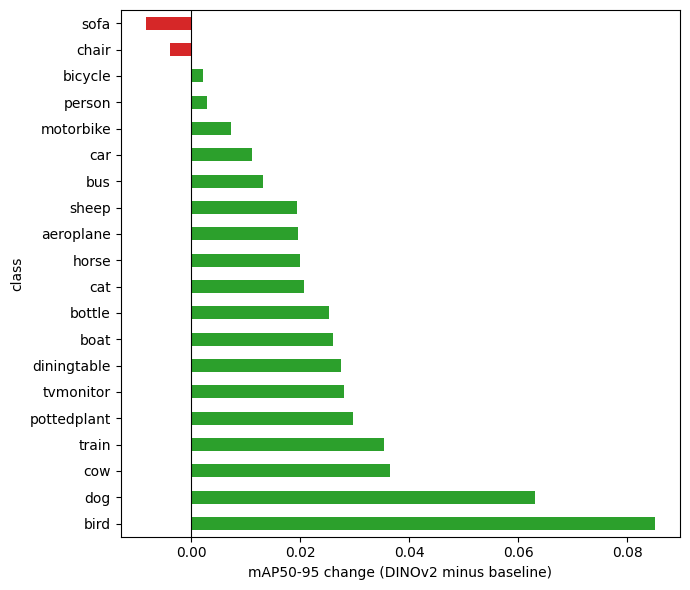

,class,baseline,dino,change
2,bird,0.5512,0.6362,0.0850
11,dog,0.6738,0.7368,0.0630
9,cow,0.6656,0.7020,0.0364
18,train,0.6643,0.6997,0.0354
15,pottedplant,0.3449,0.3746,0.0297
19,tvmonitor,0.6310,0.6591,0.0280
10,diningtable,0.6178,0.6452,0.0274
3,boat,0.5171,0.5430,0.0260
4,bottle,0.5170,0.5423,0.0253
7,cat,0.7293,0.7500,0.0207


In [13]:
if len(metrics) == 2:
    names = models["baseline"].names
    per_class = pd.DataFrame({
        "class": [names[i] for i in metrics["baseline"].box.ap_class_index],
        "baseline": metrics["baseline"].box.ap,
        "dino": metrics["dino"].box.ap,
    })
    per_class["change"] = per_class["dino"] - per_class["baseline"]
    per_class = per_class.sort_values("change", ascending=False).round(4)
    per_class.to_csv(os.path.join(WORK, "results", "per_class.csv"), index=False)
    ax = per_class.plot.barh(x="class", y="change", legend=False, figsize=(7, 6),
                             color=["tab:green" if c >= 0 else "tab:red" for c in per_class["change"]])
    ax.axvline(0, color="black", lw=0.8); ax.set_xlabel("mAP50-95 change (DINOv2 minus baseline)")
    plt.tight_layout(); plt.savefig(os.path.join(WORK, "results", "per_class_change.png"), dpi=150); plt.show()
    display(per_class)

### 13.1 Observations
- **18 of 20 classes improved.** Only *chair* (−0.4 points) and *sofa* (−0.8 points) decreased slightly.
- **Animals benefit most:** *bird* +8.5, *dog* +6.3, *cow* +3.6, *cat* +2.1, *horse* +2.0, *sheep* +1.9. These classes look similar to each other (fur, four legs) and appear in many poses, so YOLO's local textures are often ambiguous. DINOv2's self-supervised features capture object identity and typical surroundings (sky for birds, fields for cows and sheep), which helps tell them apart.
- **Context-defined classes also gain:** *train* +3.5 (tracks, stations), *boat* +2.6 (water), *aeroplane* +2.0 (sky, runway).
- **Person barely changes (+0.3).** It has by far the most training examples (13,256), so YOLO already learns it well from labels alone; the pre-trained knowledge adds most where task data is less sufficient.
- **Chair and sofa decline slightly.** These appear in cluttered indoor scenes full of similar furniture, often partly hidden. A whole-image summary ("living room") does not say *which* object is the chair, and it may push the model towards the wrong furniture class. Changes this small may also be within run-to-run variation.
- The weakest classes remain the same for both models (*potted plant* 0.375, *chair* 0.468). These are small, cluttered or heavily occluded objects, where a single global embedding cannot provide the missing local detail.

## 14. Training curves
Validation mAP50-95 and validation classification loss after every epoch, for both models.

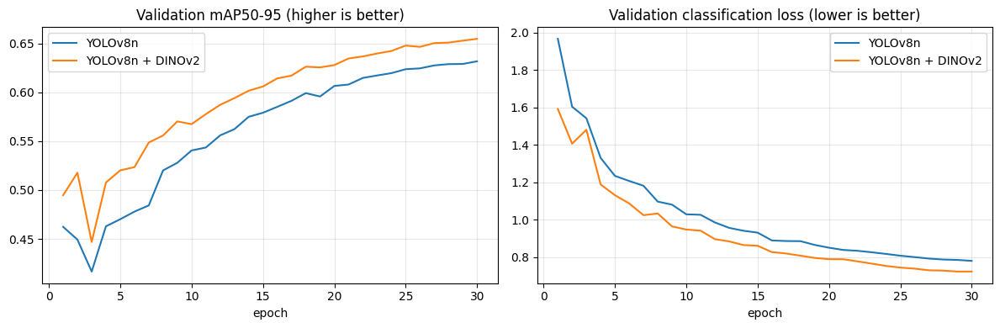

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, label in [("baseline", "YOLOv8n"), ("dino", "YOLOv8n + DINOv2")]:
    f = os.path.join(RUNS, name, "results.csv")
    if os.path.exists(f):
        r = pd.read_csv(f); r.columns = r.columns.str.strip()
        axes[0].plot(r["epoch"], r["metrics/mAP50-95(B)"], label=label)
        axes[1].plot(r["epoch"], r["val/cls_loss"], label=label)
axes[0].set_title("Validation mAP50-95 (higher is better)"); axes[1].set_title("Validation classification loss (lower is better)")
for a in axes: a.set_xlabel("epoch"); a.legend(); a.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(os.path.join(WORK, "results", "training_curves.png"), dpi=150); plt.show()

### 14.1 Observations
- The DINOv2 model is **ahead at every epoch**, not just at the end. This consistent gap makes it unlikely that the final difference is due to a lucky epoch.
- It is ahead from the very first epoch. The pre-trained features give a useful head start, so the detector adapts to the new dataset faster.
- Its **classification loss** (errors about *what* an object is) is lower throughout. This supports the idea that DINOv2 helps mainly with recognition, not with box localisation.
- Both curves are still slowly rising at epoch 30, so longer training would likely improve both models further.

## 15. Example detections
Four evenly spaced test photos, detected by the baseline (left) and by YOLOv8n + DINOv2 (right). Only boxes with confidence of at least 0.25 are drawn.

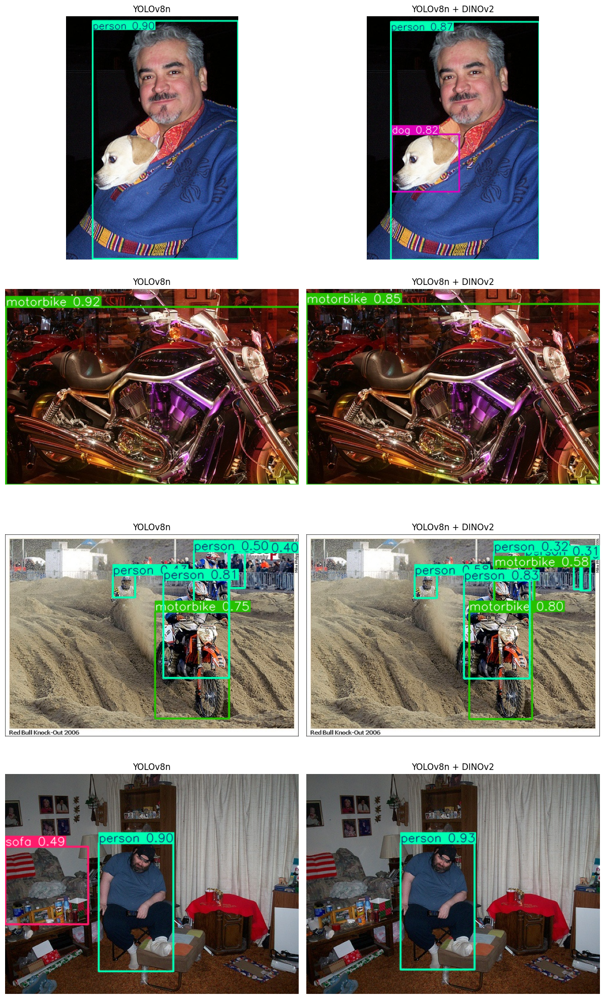

In [15]:
if len(models) == 2 and val_images:
    samples = val_images[::max(len(val_images) // 4, 1)][:4]
    fig, axes = plt.subplots(len(samples), 2, figsize=(12, 5 * len(samples)))
    axes = axes.reshape(len(samples), 2)
    for row, img in enumerate(samples):
        for col, name in enumerate(["baseline", "dino"]):
            res = models[name].predict(img, imgsz=IMGSZ, device=DEVICE, conf=0.25, verbose=False)[0]
            axes[row, col].imshow(res.plot()[:, :, ::-1]); axes[row, col].axis("off")
            axes[row, col].set_title("YOLOv8n" if name == "baseline" else "YOLOv8n + DINOv2")
    plt.tight_layout(); plt.savefig(os.path.join(WORK, "results", "examples.png"), dpi=120); plt.show()

## 16. Per-class qualitative comparison on random test photos
For **every class**, one random test photo containing that class is picked and shown three times: the ground truth (green boxes = the class of that row), the baseline YOLOv8n, and YOLOv8n + DINOv2.
Under each model: **correct** = boxes of that class overlapping a real object by at least 50% (IoU ≥ 0.5), **missed** = real objects of that class not found, **wrong** = extra boxes of that class that match nothing.
Change `GALLERY_SEED` to see a different random photo for each class.

Showing 1 random test photo for each of 20 classes (seed=42).
Columns: ground truth | YOLOv8n | YOLOv8n + DINOv2.   Counts refer to the class named on the left.



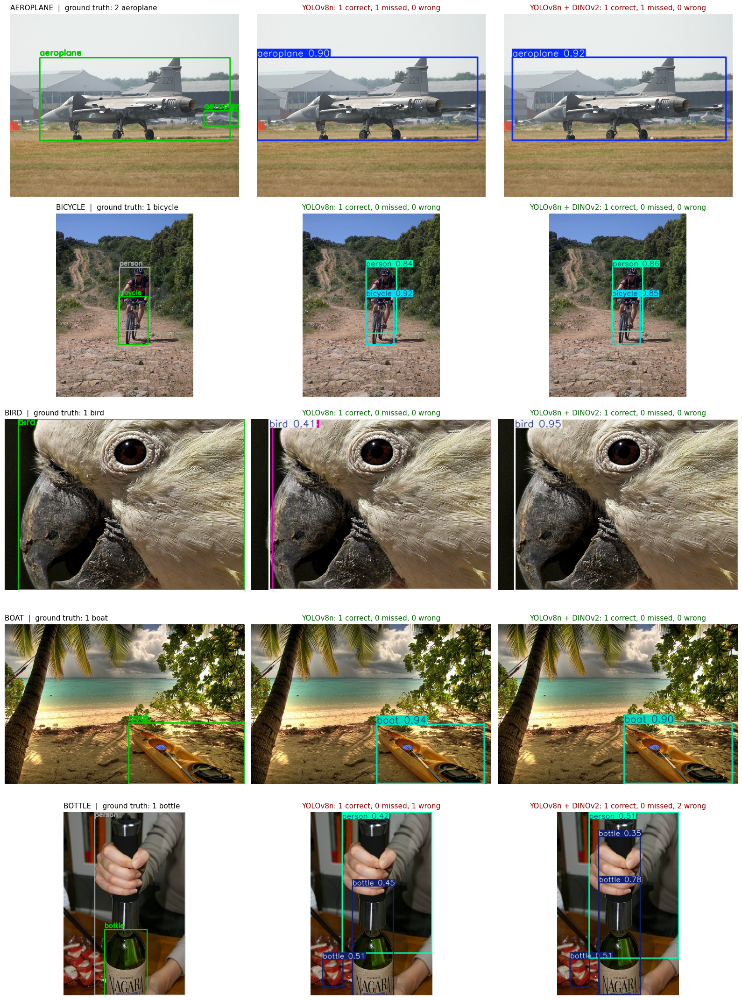

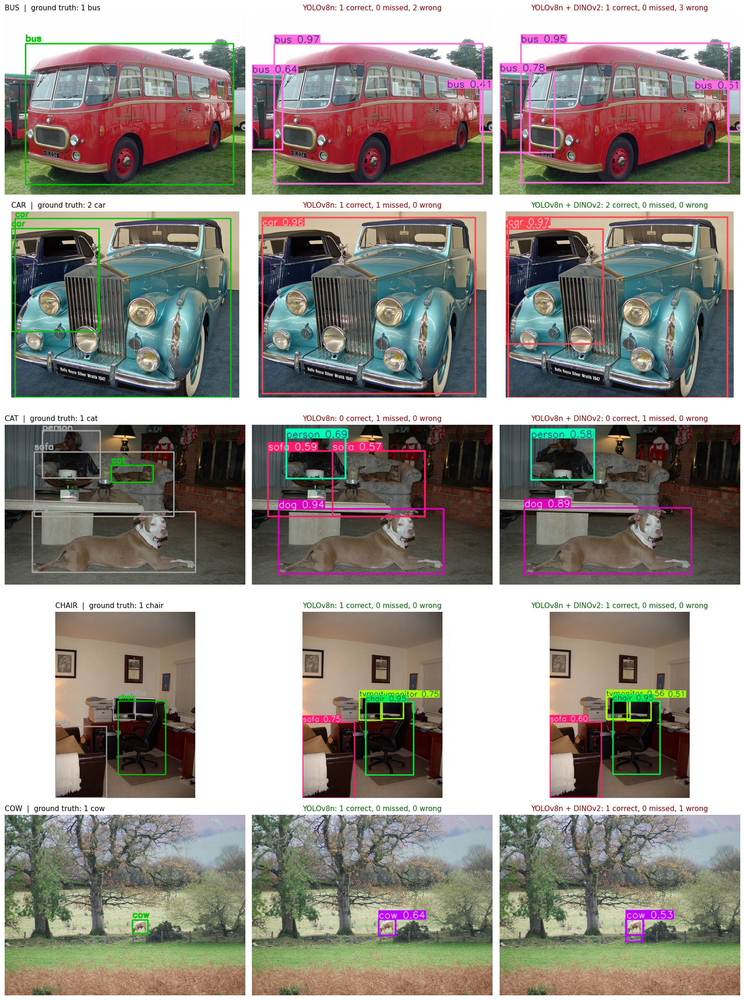

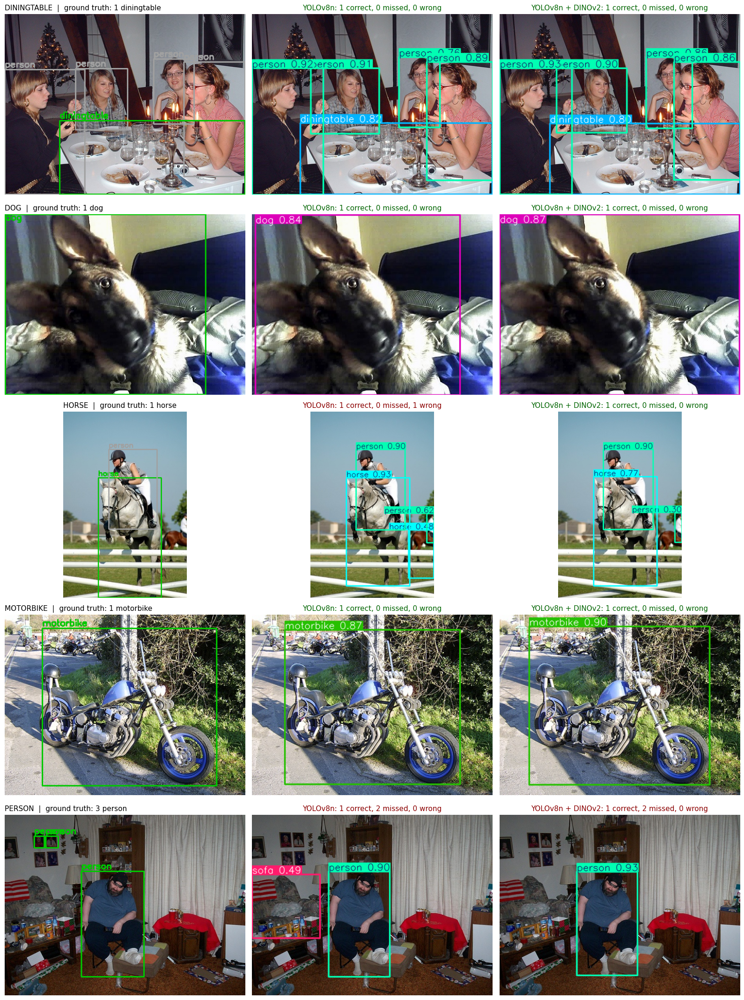

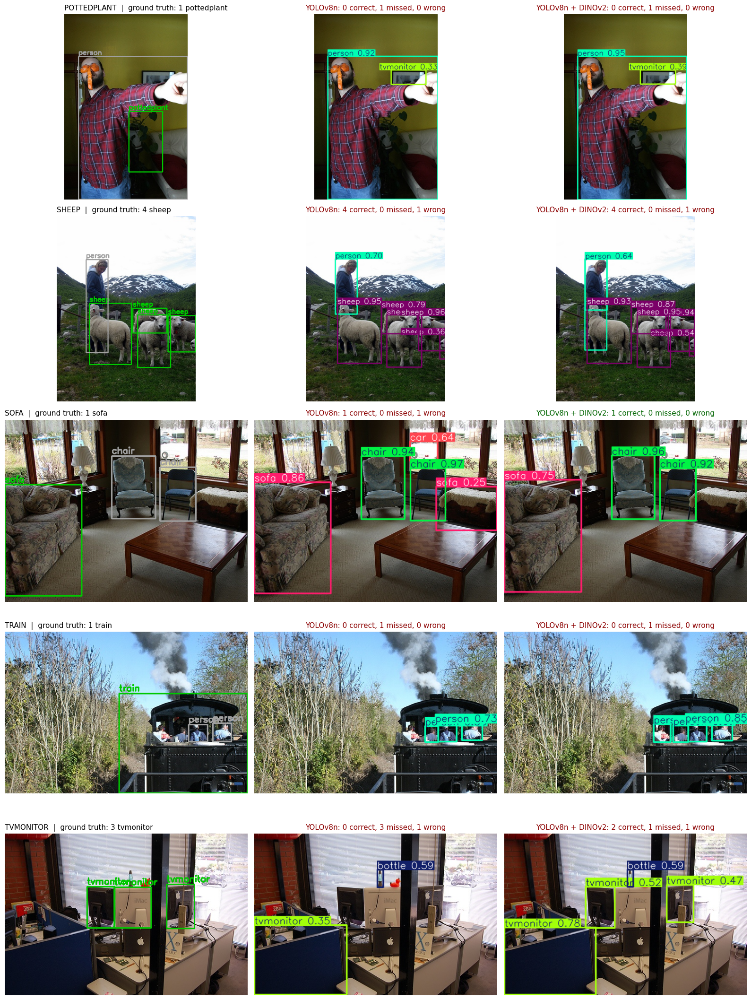

Totals over these photos (for the class of each row):


,correct,missed,wrong
YOLOv8n,19,10,7
YOLOv8n + DINOv2,22,7,8


In [16]:
import random, glob, cv2, torch
import numpy as np
from ultralytics.data.utils import check_det_dataset, img2label_paths
from ultralytics.utils.metrics import box_iou

GALLERY_SEED = 42    # change this number to get a different random photo for each class
CONF = 0.25          # only boxes the model is at least 25% sure about are shown
ROWS_PER_PAGE = 5    # classes per figure (20 VOC classes -> 4 figures)

info = check_det_dataset(DATA)
names = info["names"]
test_imgs = sorted(glob.glob(os.path.join(val_dir, "*.jpg")))   # test photos: never used for training

def read_truth(img):
    """Ground-truth boxes of a photo, in pixels: class ids and [x1, y1, x2, y2]."""
    h, w = cv2.imread(img).shape[:2]
    cls, boxes = [], []
    lab = img2label_paths([img])[0]
    if os.path.exists(lab):
        for line in open(lab):
            c, xc, yc, bw, bh = int(line.split()[0]), *map(float, line.split()[1:5])
            cls.append(c); boxes.append([(xc - bw / 2) * w, (yc - bh / 2) * h, (xc + bw / 2) * w, (yc + bh / 2) * h])
    return torch.tensor(cls), torch.tensor(boxes).reshape(-1, 4)

# Index: which test photos contain each class
by_class = {c: [] for c in names}
for img in test_imgs:
    lab = img2label_paths([img])[0]
    if os.path.exists(lab):
        for c in {int(l.split()[0]) for l in open(lab) if l.strip()}:
            by_class[c].append(img)

def score(pred, truth_boxes, target):
    """For the target class: correct boxes (overlap >= 50% with a real object), missed objects, wrong boxes."""
    p = pred.boxes
    pb = p.xyxy[(p.cls.cpu() == target)].cpu()
    if len(truth_boxes) == 0 or len(pb) == 0:
        return 0, len(truth_boxes), len(pb)
    iou = box_iou(truth_boxes, pb)
    correct = 0
    while iou.numel() and iou.max() >= 0.5:          # greedy one-to-one matching
        i, j = divmod(int(iou.argmax()), iou.shape[1])
        correct += 1; iou[i, :] = 0; iou[:, j] = 0
    return correct, len(truth_boxes) - correct, len(pb) - correct

rng = random.Random(GALLERY_SEED)
picks = [(c, rng.choice(by_class[c])) for c in names if by_class[c]]
print(f"Showing 1 random test photo for each of {len(picks)} classes (seed={GALLERY_SEED}).")
print("Columns: ground truth | YOLOv8n | YOLOv8n + DINOv2.   Counts refer to the class named on the left.\n")

tally = {"baseline": [0, 0, 0], "dino": [0, 0, 0]}
for page in range(0, len(picks), ROWS_PER_PAGE):
    chunk = picks[page:page + ROWS_PER_PAGE]
    fig, axes = plt.subplots(len(chunk), 3, figsize=(16, 4.3 * len(chunk)))
    axes = np.array(axes).reshape(len(chunk), 3)
    for r, (c, img) in enumerate(chunk):
        t_cls, t_boxes = read_truth(img)
        target_boxes = t_boxes[t_cls == c]
        gt = cv2.imread(img)
        for k, b in zip(t_cls.tolist(), t_boxes.tolist()):
            colour = (0, 200, 0) if k == c else (160, 160, 160)   # green = the class of this row
            cv2.rectangle(gt, (int(b[0]), int(b[1])), (int(b[2]), int(b[3])), colour, 2)
            cv2.putText(gt, names[k], (int(b[0]), max(int(b[1]) - 5, 12)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, colour, 2)
        axes[r, 0].imshow(gt[:, :, ::-1])
        axes[r, 0].set_title(f"{names[c].upper()}  |  ground truth: {len(target_boxes)} {names[c]}", fontsize=11, loc="left")
        for col, (key, label) in enumerate([("baseline", "YOLOv8n"), ("dino", "YOLOv8n + DINOv2")], start=1):
            pred = models[key].predict(img, imgsz=IMGSZ, device=DEVICE, conf=CONF, verbose=False)[0]
            ok, missed, wrong = score(pred, target_boxes, c)
            for i, v in enumerate((ok, missed, wrong)): tally[key][i] += v
            axes[r, col].imshow(pred.plot()[:, :, ::-1])
            axes[r, col].set_title(f"{label}: {ok} correct, {missed} missed, {wrong} wrong", fontsize=11,
                                   color="darkgreen" if missed == 0 and wrong == 0 else "darkred")
        for a in axes[r]: a.axis("off")
    plt.tight_layout()
    plt.savefig(os.path.join(WORK, "results", f"per_class_examples_{page // ROWS_PER_PAGE + 1}.png"), dpi=100)
    plt.show()

print("Totals over these photos (for the class of each row):")
display(pd.DataFrame(tally, index=["correct", "missed", "wrong"]).rename(columns={"baseline": "YOLOv8n", "dino": "YOLOv8n + DINOv2"}).T)

### 16.1 Observations
Totals over the 20 randomly chosen photos (for the class of each row):

| | Correct | Missed | Wrong |
|---|---|---|---|
| YOLOv8n | 19 | 10 | 7 |
| YOLOv8n + DINOv2 | **22** | **7** | 8 |

- The DINOv2 model found **3 more** objects and missed **3 fewer**, at the cost of one extra wrong box. This is the same pattern as the full test set, on a small sample.
- **Bird (close-up of a cockatoo):** both models detect it, but the baseline is only **41%** confident while the DINOv2 model is **95%** confident. Without the full shape of a bird in view, YOLO's local features are weak evidence, while DINOv2 recognises the image as a bird photo as a whole.
- **Bottle (hand holding a bottle):** the DINOv2 model adds an extra, incorrect bottle box. In cluttered close-ups the global hint can increase confidence in the wrong region, the same weakness seen for chair and sofa.
- With only one photo per class, these examples are **illustrations**. The quantitative evidence is the evaluation on all 4,952 test photos in Section 12.

## 17. Saving outputs
All tables and charts in `/kaggle/working/results` are packed into `project_results.zip`. The trained models are in `runs/baseline/weights/best.pt` and `runs/dino/weights/best.pt`.

In [17]:
import shutil
shutil.make_archive(os.path.join(WORK, "project_results"), "zip", WORK, "results")
print("Saved:", sorted(os.listdir(os.path.join(WORK, "results"))))

Saved: ['dataset_class_counts.png', 'dataset_per_class.csv', 'dataset_samples.png', 'dataset_stats.png', 'dataset_summary.csv', 'examples.png', 'per_class.csv', 'per_class_change.png', 'per_class_examples_1.png', 'per_class_examples_2.png', 'per_class_examples_3.png', 'per_class_examples_4.png', 'summary.csv', 'training_curves.png']


## 18. Discussion: the utility of the pre-trained model
**What DINOv2 contributes.** YOLOv8 learns from about 16,500 labelled VOC photos (plus its COCO pre-training). DINOv2 brings knowledge from about 142 million unlabelled images, a scale no labelled detection dataset reaches. Its global embedding encodes *what the scene is about*, and that is passed to YOLO as context at almost no training cost, since DINOv2 is frozen.

**Evidence of utility from this experiment**
1. **Accuracy:** +2.3 points mAP50-95 (0.632 → 0.655), with higher precision *and* recall, under identical training conditions.
2. **Breadth:** 18 of 20 classes improve. The largest gains are for visually ambiguous, context-dependent classes such as birds, dogs and cows.
3. **Learning speed:** the model is ahead from the first epoch onward, so the pre-trained features help the detector adapt faster.
4. **Confidence:** in qualitative examples, correct detections are made with much higher confidence (bird: 0.41 → 0.95).
5. **Low training cost:** only about 0.16 M new trainable parameters, and only about 11% more training time.

**When the hint does not help.** In cluttered indoor scenes with several similar objects (chair, sofa), one summary of the whole image cannot say which region is which object, and the effect is slightly negative. Using DINOv2's per-patch features instead of the single global token would give *spatial* context and is a natural improvement.

**Trade-off.** Inference is about 2.1 times slower (11.7 → 24.1 ms per image on a T4), and the model file grows from 6 MB to 51 MB. For offline or server-side analysis the accuracy gain is worth it. On edge devices, the cost could be reduced by running DINOv2 once per scene, for example once per video shot rather than on every frame, since the scene context changes slowly.

## 19. Conclusion
Injecting the global embedding of a frozen, self-supervised DINOv2 model into the deepest layer of YOLOv8n improved object detection on Pascal VOC from **0.632 to 0.655 mAP50-95** (+3.6% relative), with gains in 18 of 20 classes and consistent gains throughout training, at the cost of about twice the inference time. A large pre-trained foundation model can therefore make a small, fast detector more accurate by supplying scene-level understanding it could not learn from its own training labels alone.

## 20. Limitations and future work
- **Extra capacity vs. pre-trained knowledge.** The fusion layer adds a small number of trainable parameters (about 0.16 M). A control run with the DINOv2 embedding replaced by zeros or random noise would show how much of the gain comes from DINOv2's knowledge itself.
- **Test set used for model selection.** Following the standard Ultralytics VOC configuration, the VOC2007 test set is also used to pick each model's best epoch. This applies equally to both models, but a separate validation split would give a stricter estimate.
- **Single run per model.** Each model was trained once with seed 0. The results are reproducible (a second run gave identical numbers), but variation across different seeds was not measured.
- **Global context only.** Only the single CLS embedding is used; DINOv2's patch features, a larger DINOv2 or YOLO model, and longer training were not explored.
- **One dataset.** Results on more cluttered datasets with more small objects (for example COCO) may differ, since VOC's objects are mostly large.

## References
1. IISc I3D Lab, *AI resource for Design & Manufacturing: YOLOv8 + DINOv2*. https://cambum.net/I3DLab/AI4DM.htm
2. M. Oquab et al., *DINOv2: Learning Robust Visual Features without Supervision*, arXiv:2304.07193, 2023.
3. G. Jocher, A. Chaurasia, J. Qiu, *Ultralytics YOLOv8*, 2023. https://github.com/ultralytics/ultralytics
4. M. Everingham et al., *The PASCAL Visual Object Classes (VOC) Challenge*, International Journal of Computer Vision, 88(2), 2010.
5. T.-Y. Lin et al., *Microsoft COCO: Common Objects in Context*, ECCV 2014.